# Step 7b: Candidate 1 of 4, XGBoost on raw £

Same rules as 7a: the winner is chosen by **R² in £** (MAE breaks ties), from **5-fold CV on train only**; tuned with **Optuna** (250 trials); features **R, F, M only**; **test is not touched**.

## The model
XGBoost = many small decision trees added one after another, each correcting the previous ones' mistakes. It predicts **in £ directly** (squared-error objective): no log, nothing to convert back. Trees don't care about feature scale, so there is no log or scaling of R, F, M either.

## What Optuna tunes (5 settings)
| Setting | Meaning | Range searched |
|---|---|---|
| `n_estimators` | number of trees | 50 to 500 |
| `max_depth` | how deep each tree can go (more depth = more complex) | 2 to 6 |
| `learning_rate` | how big a correction each new tree makes | 0.01 to 0.3 (log scale) |
| `subsample` | share of customers each tree sees | 0.3 to 1.0 |
| `colsample_bytree` | share of features each tree sees | 0.5 to 1.0 |

Code: `src/step7b_xgboost.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from metrics import r2
from step3_split import load_ledger, make_snapshot, TRAIN_CUTOFF
from step4_rfm import build_rfm
from step6_baselines import BASELINES, cv_predictions, score_table
from step7a_ridge_log import LogRidge
from step7b_xgboost import XGBModel, suggest_xgb, oof_with_seed, N_TRIALS, ALPHA_7A_SMEAR
from tuning import tune

pd.set_option("display.width", 200)
train = make_snapshot(load_ledger(), TRAIN_CUTOFF)
X, y = build_rfm(train), train.target
ya = y.to_numpy()

/data/home/mitanshub/miniconda3/envs/ml_clv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Tune with Optuna

{'n_estimators': 480, 'max_depth': 5, 'learning_rate': 0.0111, 'subsample': 0.3009, 'colsample_bytree': 0.5686}
best CV R2 (tuning score): 0.503


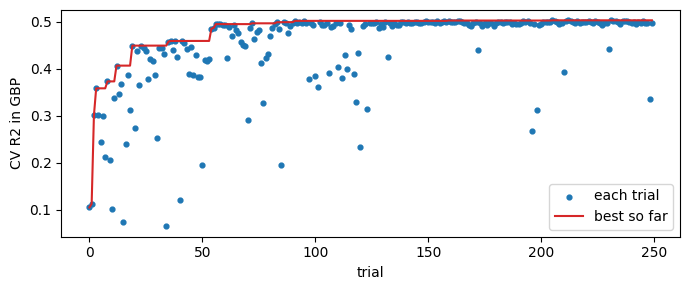

In [2]:
study = tune(lambda **p: XGBModel(**p), suggest_xgb, X, y, n_trials=N_TRIALS)
best = study.best_params
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in best.items()})
print(f"best CV R2 (tuning score): {study.best_value:.3f}")

vals = [t.value for t in study.trials]
fig, ax = plt.subplots(figsize=(7, 3))
ax.scatter(range(len(vals)), vals, s=12, label="each trial")
ax.plot(np.maximum.accumulate(vals), color="tab:red", label="best so far")
ax.set_xlabel("trial"); ax.set_ylabel("CV R2 in GBP"); ax.legend(); plt.tight_layout()

The winning settings are **480 trees of depth 5 with a very small learning rate (0.011)**, each tree seeing only about 30% of the customers and 57% of the features. In words: many small, slow, deliberately noisy trees.

Notice that three settings landed right at the edge of their search range: `n_estimators` 480 (max 500), `learning_rate` 0.0111 (min 0.01) and `subsample` 0.30 (min 0.3). When the best value keeps sitting on the edge, the score landscape is probably a flat plateau where "more regularization" is slightly better. Widening the ranges further is unlikely to change the story.

(History: the first run used 30 trials and `subsample` 0.5 to 1.0. It found 88 trees of depth 3 and a tuning score of 0.453. With 250 trials the tuning score is 0.503. Section 2 shows how much of that gain is real.)

## 2. Compare (train CV)

In [3]:
preds = {n: cv_predictions(c, X, y) for n, c in BASELINES.items()}
preds["LogRidge + smearing (7a)"] = cv_predictions(lambda: LogRidge(ALPHA_7A_SMEAR, True), X, y)
preds["XGBoost raw GBP (7b)"] = cv_predictions(lambda: XGBModel(**best), X, y)

t = score_table(ya, preds)
t["total pred / total actual"] = [preds[k].sum() / ya.sum() for k in t.index]
display(t.round(3))
print("Same, without the 10 biggest customers:")
display(score_table(ya, preds, without_top=10).round(3))

,R2,MAE,Capture@20%,total pred / total actual
mean,-0.000,944.129,0.170,1.000
past_spend,0.746,523.153,0.739,1.001
LogRidge + smearing (7a),0.549,575.161,0.722,0.992
XGBoost raw GBP (7b),0.503,600.495,0.711,1.001


Same, without the 10 biggest customers:


,R2,MAE,Capture@20%
mean,-0.006,821.868,0.186
past_spend,0.549,471.154,0.686
LogRidge + smearing (7a),0.500,498.504,0.666
XGBoost raw GBP (7b),0.322,532.037,0.651


Is the tuning score optimistic? Optuna chose these settings on one particular fold split. Re-score the same settings on 10 *other* fold splits:

In [4]:
rs = [r2(ya, oof_with_seed(lambda: XGBModel(**best), X, y, s)) for s in range(10)]
print(f"R2 on 10 other fold splits: mean {np.mean(rs):.3f}, sd {np.std(rs):.3f}, range {min(rs):.3f} to {max(rs):.3f}")
print(f"tuning score on the fold split Optuna saw: {study.best_value:.3f}")

R2 on 10 other fold splits: mean 0.478, sd 0.022, range 0.436 to 0.517
tuning score on the fold split Optuna saw: 0.503


**The tuning score (0.50) is optimistic.** The same settings score 0.478 on average on other fold splits (range 0.44 to 0.52). The more combinations Optuna tries, the more likely one looks good on these particular folds by luck.

**Going from 30 to 250 trials raised the tuning score from 0.45 to 0.50, but the honest estimate barely moved (0.475 to 0.478).** So the extra tuning mostly bought a better-looking number, not a better model. Either way XGBoost is well below past spend (0.75).

## 3. Why does a more flexible model lose on R² in £?

Hypothesis: trees predict *averages of the training customers in a group*, so they cannot predict higher than the biggest values they have seen, while past spend (`0.37 × Monetary`) keeps scaling for any size. Look at the biggest past spenders (out-of-fold predictions):

In [5]:
d = pd.DataFrame({"Monetary": X["Monetary"], "actual": ya,
                  "past_spend": preds["past_spend"], "xgboost": preds["XGBoost raw GBP (7b)"]})
display(d.nlargest(8, "Monetary").round(0))
xg = preds["XGBoost raw GBP (7b)"]
print(f"largest XGBoost prediction: {xg.max():,.0f} | largest actual spend: {ya.max():,.0f}")
for n in ("past_spend", "XGBoost raw GBP (7b)"):
    e = (ya - preds[n]) ** 2; top = np.argsort(-ya)[:10]
    print(f"{n:22s} share of total squared error from the 10 biggest actual customers: {e[top].sum() / e.sum():.0%}")

,Monetary,actual,past_spend,xgboost
Customer ID,,,,
18102,318751.0,92477.0,120142.0,32078.0
14646,245028.0,110668.0,89681.0,30266.0
14156,185106.0,41661.0,70210.0,43079.0
14911,132744.0,38486.0,48251.0,28902.0
13694,127430.0,27171.0,48334.0,43215.0
17511,80366.0,38871.0,29414.0,18022.0
16684,75610.0,24923.0,28499.0,18737.0
15061,70732.0,41989.0,26828.0,54147.0


largest XGBoost prediction: 54,147 | largest actual spend: 110,668
past_spend             share of total squared error from the 10 biggest actual customers: 55%
XGBoost raw GBP (7b)   share of total squared error from the 10 biggest actual customers: 66%


That matches the hypothesis. XGBoost never predicts above about £54k, while real spend reaches £110k, and for the customer with £319k past spend it predicts £32k where past spend predicts £120k (actual £92k). About 66% of XGBoost's total squared error comes from just the 10 biggest customers.

MAE tells a milder version of the same story (600 vs 523): XGBoost is also a bit worse for ordinary customers, so it is not *only* the giants.

## 4. What XGBoost relies on

In [6]:
imp = pd.Series(XGBModel(**best).fit(X, y).model_.feature_importances_, index=X.columns)
display(imp.round(3).to_frame("importance"))
print("Spearman rank correlation of each feature with the target:")
display(X.assign(target=ya).corr(method="spearman")["target"].drop("target").round(3).to_frame("Spearman"))

,importance
Recency,0.050
Frequency,0.537
Monetary,0.414


Spearman rank correlation of each feature with the target:


,Spearman
Recency,-0.376
Frequency,0.544
Monetary,0.549


Frequency and Monetary carry almost all the weight; Recency gets only about 5% of the trees' weight, although it correlates with the target at about -0.38. Frequency and Monetary overlap, and once they are in, Recency adds little.

## What we learned

| Train CV | R² | MAE (£) | Capture@20% | total pred / total actual |
|---|---|---|---|---|
| mean | 0.00 | 944 | 0.17 | 1.00 |
| **past_spend** | **0.75** | **523** | **0.74** | 1.00 |
| Ridge on log1p + smearing (7a) | 0.55 | 575 | 0.72 | 0.99 |
| **XGBoost raw £ (7b)** | 0.50 (honest estimate 0.48) | 600 | 0.71 | 1.00 |

- **XGBoost does not beat past spend**, and is also below the 7a Ridge (0.50 vs 0.55 on the tuning score, 0.48 vs 0.56 on the honest fold-splits estimate). MAE is worse than 7a too (600 vs 575).
- **Totals are well calibrated** (predicted total / actual total is 1.00), unlike the plain log model.
- **Ranking is a tie again** (0.71 vs 0.74, inside the ±0.04 noise).
- **The reason is the giants.** With only R, F, M and about 4,000 customers, a handful of huge customers decide R² in £. Trees cannot extrapolate to them; the linear past-spend rule can. Without the 10 biggest customers XGBoost's R² is 0.32, vs 0.50 for the 7a Ridge and 0.55 for past spend.
- **More tuning did not help for real:** 30 to 250 trials lifted the tuning score by 0.05 but the honest estimate by only 0.003.

**Ideas to fix the giants problem (not tried, for discussion):** (a) predict the *ratio* `target / Monetary` instead of £, so the model corrects the linear rule instead of replacing it; (b) add features that tell big customers apart (step 8+).

**Current standing by R² (train CV):** past_spend 0.75 &gt; Ridge+smearing 0.55 &gt; XGBoost 0.50 (tuning score; honest estimate 0.48) &gt; Ridge plain 0.40 &gt; mean 0.00.

**Next (step 7c):** Tweedie, which is built for data with many zeros and a heavy right tail.